# Lab 3.2 — From one attention head to a tiny decoder

Lab 3.1 asked for one answer at the final position. Here every character asks a question. Given everything visible from my position, which character comes next?

## 1. Turn one line into many predictions

Slide the target one place to the left. For the five-character snippet `ROMEO`, the inputs are `ROME` and the targets are `OMEO`. The row at M can read R, O and M. It gets a reward for assigning probability to E. **Teacher forcing** supplies the real preceding characters during training. The causal mask lets us score all four rows in one forward pass.

Use the same Tiny Shakespeare corpus as Lab 2.2. Reserve the last tenth before drawing windows so a training window can never cross into the test text.

In [1]:
from pathlib import Path
import math
import sys
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import Image, display

sys.path.insert(0, str(Path("../lm-internals").resolve()))
from lm_lab import save_ckpt, load_ckpt

torch.manual_seed(32)
torch.set_num_threads(1)
path = Path("../lm-internals/data/tiny-shakespeare.txt")
if not path.exists():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    with urlopen(url, timeout=30) as response:
        corpus = response.read().decode("utf-8")
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(corpus, encoding="utf-8")
text = path.read_text(encoding="utf-8")
cut = 9 * len(text) // 10
alphabet = sorted(set(text[:cut]))
index = {ch: i for i, ch in enumerate(alphabet)}
ids = torch.tensor([index[ch] for ch in text])
train, test = ids[:cut], ids[cut:]
V, T, D = len(alphabet), 32, 48

def windows(stream, starts):
    chunk = stream[starts[:, None] + torch.arange(T + 1)]
    return chunk[:, :-1], chunk[:, 1:]

for end in range(1, len("ROMEO")):
    print(repr("ROMEO"[:end]), "→", repr("ROMEO"[end]))

'R' → 'O'
'RO' → 'M'
'ROM' → 'E'
'ROME' → 'O'


## 2. Assemble one decoder block

Start each row with a character embedding plus a learned position embedding. This lets the head distinguish the first R in a window from an R three places later. Use the same scaled, masked dot products as Lab 3.1.

Read the two additions in the forward pass separately. Attention writes a mixture of information from visible positions into each row. The feedforward network then transforms each row independently, using the same weights at every position. Each addition is a **residual connection** that carries the original row forward alongside the update. **Layer normalization** rescales each row across its features before computing each update.

Finally, a linear readout gives one score per vocabulary character at every position. Before training, change the last input and predict which rows of scores can move.

In [2]:
class TinyDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.token = nn.Embedding(V, D)
        self.position = nn.Embedding(T, D)
        self.norm1 = nn.LayerNorm(D)
        self.qkv = nn.Linear(D, 3 * D)
        self.attn_out = nn.Linear(D, D)
        self.norm2 = nn.LayerNorm(D)
        self.ff = nn.Sequential(nn.Linear(D, 2 * D), nn.GELU(), nn.Linear(2 * D, D))
        self.readout = nn.Sequential(nn.LayerNorm(D), nn.Linear(D, V))

    def forward(self, tokens):
        length = tokens.size(1)
        x = self.token(tokens) + self.position(torch.arange(length))
        q, k, v = self.qkv(self.norm1(x)).chunk(3, dim=-1)
        scores = q @ k.transpose(-1, -2) / math.sqrt(D)
        future = torch.ones(length, length, dtype=torch.bool).triu(1)
        weights = scores.masked_fill(future, -torch.inf).softmax(-1)
        x = x + self.attn_out(weights @ v)
        x = x + self.ff(self.norm2(x))
        return self.readout(x)

model = TinyDecoder()
probe = torch.tensor([[index[c] for c in "ROME"]])
edited = probe.clone()
edited[0, -1] = index["A"]
with torch.no_grad():
    original, changed = model(probe), model(edited)
torch.testing.assert_close(original[:, :-1], changed[:, :-1])
assert not torch.allclose(original[:, -1], changed[:, -1])
print("Input shape:", tuple(probe.shape), "→ logit shape:", tuple(original.shape))

Input shape: (1, 4) → logit shape: (1, 4, 65)


## 3. Does extra context help on unseen text?

A **bigram model** has one distribution per current character. Count each adjacent pair in the training split and add one count to every possible pair so even unseen transitions have finite loss. This gives a baseline trained on the entire split.

Train the decoder on random windows. Measure both models on the same fixed held-out windows using mean negative log probability of the true next character. The natural logarithm gives units of **nats per character**. A lower score means the model assigned more probability to the observed next characters on average.

Held-out loss over 8,192 targets
Bigram 2.481 | decoder 2.174 nats/character


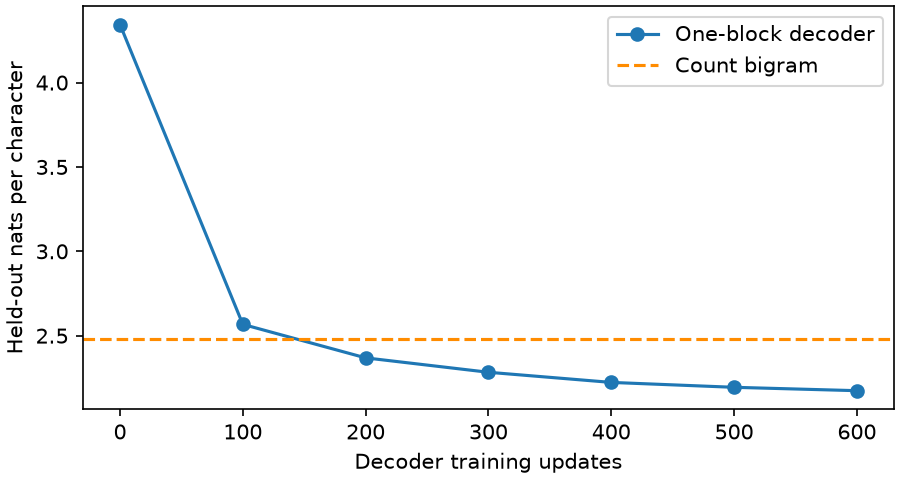

In [3]:
counts = torch.bincount(train[:-1] * V + train[1:], minlength=V * V).reshape(V, V) + 1
bigram = counts / counts.sum(1, keepdim=True)
starts = torch.linspace(0, len(test) - T - 1, 256).long()
test_x, test_y = windows(test, starts)
baseline = -bigram[test_x, test_y].log().mean().item()

def loss_on(inputs, labels):
    return F.cross_entropy(model(inputs).reshape(-1, V), labels.reshape(-1))

optimizer = torch.optim.AdamW(model.parameters(), lr=0.003)
steps, losses = [], []
for step in range(601):
    if step % 100 == 0:
        with torch.no_grad():
            losses.append(loss_on(test_x, test_y).item())
        steps.append(step)
    if step < 600:
        x, y = windows(train, torch.randint(len(train) - T, (48,)))
        optimizer.zero_grad()
        loss_on(x, y).backward()
        optimizer.step()

print(f"Held-out loss over {test_y.numel():,} targets")
print(f"Bigram {baseline:.3f} | decoder {losses[-1]:.3f} nats/character")
fig, ax = plt.subplots(figsize=(6, 3.2), layout="constrained")
ax.plot(steps, losses, marker="o", label="One-block decoder")
ax.axhline(baseline, color="darkorange", linestyle="--", label="Count bigram")
ax.set(xlabel="Decoder training updates", ylabel="Held-out nats per character")
ax.legend()
figure = Path("figures/lab32/held_out_loss.png")
figure.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure, dpi=150)
plt.close(fig)
display(Image(filename=str(figure)))

## 4. Follow one prediction into generation

Compare the two distributions after `ROM` and ` AM` (a space followed by A and M). Both prompts end in M at the same position. Predict which model must give the same answer distribution twice. Look at the top three characters before reading the samples.

During generation, sample from the last row, append the sampled character, then repeat. After 32 characters the decoder sees the most recent window. A sample shows one possible continuation. Use the held-out loss above to compare predictive accuracy.

In [4]:
@torch.no_grad()
def distribution(context, decoder):
    if decoder:
        return model(context[None, -T:])[0, -1].softmax(dim=-1)
    return bigram[context[-1]]

for prompt in ("ROM", " AM"):
    context = torch.tensor([index[c] for c in prompt])
    for decoder in (False, True):
        probs, chars = distribution(context, decoder).topk(3)
        print(prompt, "decoder" if decoder else "bigram",
              [(alphabet[i], round(p.item(), 3)) for p, i in zip(probs, chars)])

for decoder in (False, True):
    rng = torch.Generator().manual_seed(32)
    context = torch.tensor([index[c] for c in "ROMEO:"])
    for _ in range(100):
        token = torch.multinomial(distribution(context, decoder), 1, generator=rng)
        context = torch.cat([context, token])
    print("Decoder" if decoder else "Bigram", repr("".join(alphabet[i] for i in context)))

ROM bigram [('E', 0.169), ('a', 0.166), ('y', 0.156)]
ROM decoder [('E', 0.619), ('I', 0.224), (':', 0.057)]
 AM bigram [('E', 0.169), ('a', 0.166), ('y', 0.156)]
 AM decoder [('E', 0.402), ('I', 0.308), (':', 0.132)]
Bigram "ROMEO:\n\nTwi'\nALI whamy cad s tited de athehityo?\nSIUTHUMBRirty why bs n tre yo are thederinde t t s fin ha"
Decoder "ROMEO:\nAnd 'a not the on I stursed and ther, youth a tham tray why enferte by\nAUCESTES:\nDUKECE: tos for ha"


If the two decoder distributions differ after M, what has that established about context? What extra experiment would tell you whether the R or O mattered more after the prompt ROM?

### Save the model for the decoding lab

Keep the trained parameters, vocabulary order and dimensions together. The vocabulary order determines which character each logit represents. Reload the weights and compare all logits on the original probe.

In [5]:
ckpt = save_ckpt(Path("checkpoints/lab32"), "tiny_decoder", step=steps[-1],
                 metrics={"bigram_nats": baseline, "decoder_nats": losses[-1]},
                 alphabet=np.array(alphabet), context_length=np.array(T), width=np.array(D),
                 **{k: v.detach().numpy() for k, v in model.state_dict().items()})
arrays = load_ckpt(ckpt)
restored = TinyDecoder()
restored.load_state_dict({k: torch.from_numpy(arrays[k]) for k in restored.state_dict()})
with torch.no_grad():
    torch.testing.assert_close(restored(probe), model(probe))
print("Reloaded model reproduces all four rows of logits.")

Reloaded model reproduces all four rows of logits.
